# Laboratorium 6 — Przygotowanie danych dla Char-RNN
**Autor:** Oskar Pietrzak · **Grupa:** 03 · **Data:** 25.11.2026

In [1]:
%pip -q install torch numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Korpus i podział danych

In [2]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import re
import unicodedata
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
folder = Path('dane_lab_06')
wykresy = Path('wykresy_lab_06')
folder.mkdir(exist_ok=True)
wykresy.mkdir(exist_ok=True)
url = 'https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt'
plik = folder / 'lalka_zrodlo.txt'
if not plik.exists():
    plik.write_bytes(urllib.request.urlopen(url, timeout=60).read())
surowe = plik.read_bytes()
sha256 = hashlib.sha256(surowe).hexdigest()
assert sha256 == '84bc1adcb42e21e8ade9632a181b97fa50112be2b5e24044cf068cba464c6d2f'
tekst = unicodedata.normalize('NFC', surowe.decode('utf-8'))
tekst = tekst.replace('\r\n', '\n').replace('\r', '\n').replace('\xa0', ' ')
tekst = tekst[tekst.index('I. Jak wygląda firma'):].split('\n-----\n', 1)[0]
tekst = re.sub(r'[ \t]+', ' ', tekst)
tekst = re.sub(r' *\n *', '\n', tekst)
tekst = re.sub(r'\n{3,}', '\n\n', tekst).strip()
assert all(z in tekst for z in 'ąćęłńóśźż')
assert not re.search(r'<[^>]+>', tekst)
n = len(tekst)
a, b = int(0.8 * n), int(0.9 * n)
granice = {'trening': [0, a], 'walidacja': [a, b], 'test': [b, n]}
czesci = {nazwa: tekst[start:stop] for nazwa, (start, stop) in granice.items()}
assert ''.join(czesci.values()) == tekst
print('Znaków po oczyszczeniu:', n)
for nazwa, fragment in [('Początek', tekst[:180]), ('Środek', tekst[n//2:n//2+180]), ('Koniec', tekst[-180:])]:
    print(nazwa, repr(fragment))

Znaków po oczyszczeniu: 772579
Początek 'I. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?\n\nW początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo s'
Środek '\n\nUścisnął Wokulskiemu rękę, zbiegł ze wzgórza i zniknął między drzewami.\n\nNa Ogród Botaniczny i na Łazienki zapadał już mrok.\n\n„Wariat czy geniusz?… — szepnął Wokulski czując, że '
Koniec 'przypuszczać, że baba miała rację…\n\nChociaż z tym odrodzonym Stachem Wokulskim człowiek nie jest pewny. A nuż?… O, to śmiałbym się z doktora Szumana, który tak żartuje z polityki!…'


## 2. Słownik i kodowanie

In [3]:
UNK = '�'
znaki = [UNK] + sorted(set(czesci['trening']))
stoi = {z: i for i, z in enumerate(znaki)}
itos = {i: z for z, i in stoi.items()}
V = len(znaki)

def enc(s):
    return [stoi.get(z, stoi[UNK]) for z in s]

def dec(ids):
    return ''.join(itos[int(i)] for i in ids)

dane = {nazwa: torch.tensor(enc(s), dtype=torch.long) for nazwa, s in czesci.items()}
nieznane = {nazwa: Counter(z for z in s if z not in stoi) for nazwa, s in czesci.items()}
fragment = czesci['trening'][:300]
assert dec(enc(fragment)) == fragment
for nazwa, s in czesci.items():
    odtworzony = dec(dane[nazwa])
    assert odtworzony == ''.join(z if z in stoi else UNK for z in s)
    print(nazwa, 'nieznane znaki:', dict(nieznane[nazwa]), 'pełne odtworzenie:', odtworzony == s)
print('Słownik:', V, '(w tym zarezerwowany UNK)')
print('Kodowanie–dekodowanie fragmentu:', dec(enc(fragment)) == fragment)

trening nieznane znaki: {} pełne odtworzenie: True
walidacja nieznane znaki: {} pełne odtworzenie: True
test nieznane znaki: {} pełne odtworzenie: True
Słownik: 102 (w tym zarezerwowany UNK)
Kodowanie–dekodowanie fragmentu: True


## 3. Dataset, DataLoader i kontrola batchy

In [4]:
class DatasetZnakowy(Dataset):
    def __init__(self, dane, sekw):
        self.dane = dane
        self.sekw = sekw

    def __len__(self):
        return max(0, len(self.dane) - self.sekw)

    def __getitem__(self, i):
        return self.dane[i:i+self.sekw], self.dane[i+1:i+self.sekw+1]

SEKW = 40
BATCH = 32
zbiory = {nazwa: DatasetZnakowy(ids, SEKW) for nazwa, ids in dane.items()}
loadery = {
    nazwa: DataLoader(ds, batch_size=BATCH, shuffle=nazwa == 'trening',
                      drop_last=nazwa == 'trening', generator=torch.Generator().manual_seed(0))
    for nazwa, ds in zbiory.items()
}
kontrole = {}
for nazwa, loader in loadery.items():
    assert len(loader) > 0
    xb, yb = next(iter(loader))
    assert xb.shape == yb.shape == (BATCH, SEKW)
    assert xb.dtype == yb.dtype == torch.int64
    assert 0 <= xb.min() <= xb.max() < V
    assert 0 <= yb.min() <= yb.max() < V
    assert torch.equal(xb[:, 1:], yb[:, :-1])
    x, y = dec(xb[0]), dec(yb[0])
    zrodlo = ''.join(z if z in stoi else UNK for z in czesci[nazwa])
    i = zrodlo.find(x)
    assert i >= 0
    assert x == zrodlo[i:i+SEKW]
    assert y == zrodlo[i+1:i+SEKW+1]
    assert y[-1] == zrodlo[i+SEKW]
    kontrole[nazwa] = {'indeks': i, 'x': x, 'y': y, 'ksztalt': list(xb.shape),
                        'min_id': int(torch.minimum(xb.min(), yb.min())),
                        'max_id': int(torch.maximum(xb.max(), yb.max()))}
    print(nazwa, tuple(xb.shape), xb.dtype, 'ID:', kontrole[nazwa]['min_id'], '–', kontrole[nazwa]['max_id'])
    print('Indeks źródłowy:', i)
    print('Wejście:', repr(x))
    print('Cel:    ', repr(y))
    print('Ostatni znak celu:', repr(y[-1]), '— wszystkie kontrole OK')

trening (32, 40) torch.int64 ID: 1 – 101
Indeks źródłowy: 140623
Wejście: ' panna Izabela tak osłabła, że nogi zach'
Cel:     'panna Izabela tak osłabła, że nogi zachw'
Ostatni znak celu: 'w' — wszystkie kontrole OK
walidacja (32, 40) torch.int64 ID: 1 – 101
Indeks źródłowy: 0
Wejście: 'ienicę… kamienicę pana Łęckiego?…\n\n— Nic'
Cel:     'enicę… kamienicę pana Łęckiego?…\n\n— Nic '
Ostatni znak celu: ' ' — wszystkie kontrole OK
test (32, 40) torch.int64 ID: 2 – 96
Indeks źródłowy: 0
Wejście: ' pannie Izabeli Starski jako mąż, Rossi '
Cel:     'pannie Izabeli Starski jako mąż, Rossi j'
Ostatni znak celu: 'j' — wszystkie kontrole OK


## 4. Liczebności i wpływ długości okna

,Zbiór,Znaki,Udział [%],Różne znaki,Pary,Batche,Pary w batchach
0,trening,618063,80.0,101,618023,19313,618016
1,walidacja,77258,10.0,74,77218,2414,77218
2,test,77258,10.0,81,77218,2414,77218


,SEKW,trening,walidacja,test
0,40,618023,77218,77218
1,80,617983,77178,77178
2,120,617943,77138,77138


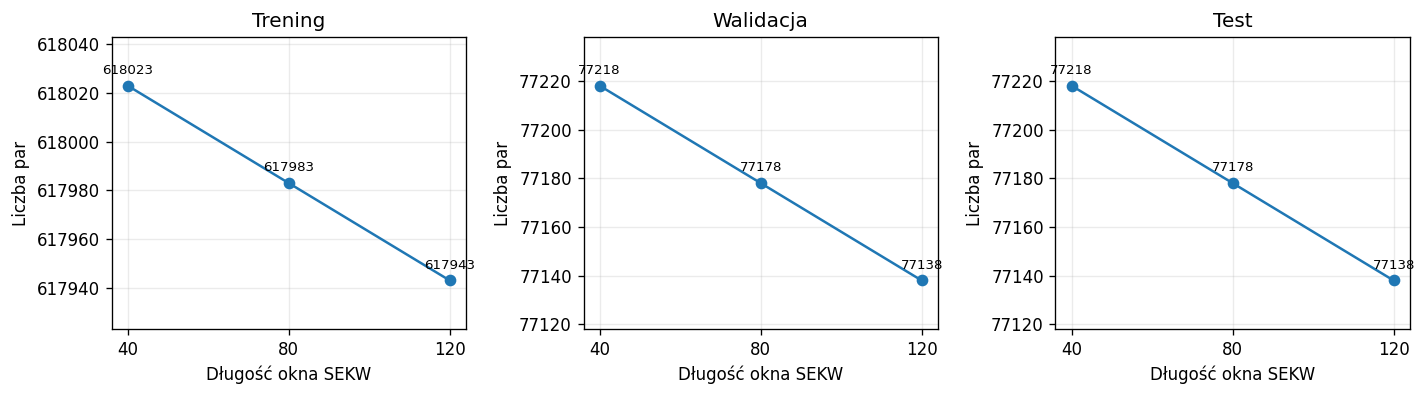

In [5]:
statystyki = pd.DataFrame([
    {'Zbiór': nazwa, 'Znaki': len(s), 'Udział [%]': 100 * len(s) / n,
     'Różne znaki': len(set(s)), 'Pary': len(zbiory[nazwa]),
     'Batche': len(loadery[nazwa]), 'Pary w batchach': len(zbiory[nazwa]) // BATCH * BATCH
     if nazwa == 'trening' else len(zbiory[nazwa])}
    for nazwa, s in czesci.items()
])
okna = [40, 80, 120]
porownanie = pd.DataFrame([
    {'SEKW': sekw, **{nazwa: len(DatasetZnakowy(ids, sekw)) for nazwa, ids in dane.items()}}
    for sekw in okna
])
display(statystyki.round(4))
display(porownanie)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, nazwa in zip(axes, czesci):
    wartosci = porownanie[nazwa]
    ax.plot(okna, wartosci, marker='o')
    for sekw, liczba in zip(okna, wartosci):
        ax.annotate(str(liczba), (sekw, liczba), xytext=(0, 7), textcoords='offset points', ha='center', fontsize=8)
    ax.set(title=nazwa.capitalize(), xlabel='Długość okna SEKW', ylabel='Liczba par', xticks=okna)
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    ax.margins(y=0.25)
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(wykresy / 'liczba_par.png', bbox_inches='tight')
plt.show()

## 5. Najczęstsze znaki i słowa w treningu

,Znak,Liczba,Udział [%]
0,spacja,93886,15.190
1,a,44128,7.140
2,i,42206,6.829
3,e,37051,5.995
4,o,34043,5.508
5,z,27753,4.490
6,n,24706,3.997
7,s,20501,3.317
8,r,19290,3.121
9,y,18477,2.990


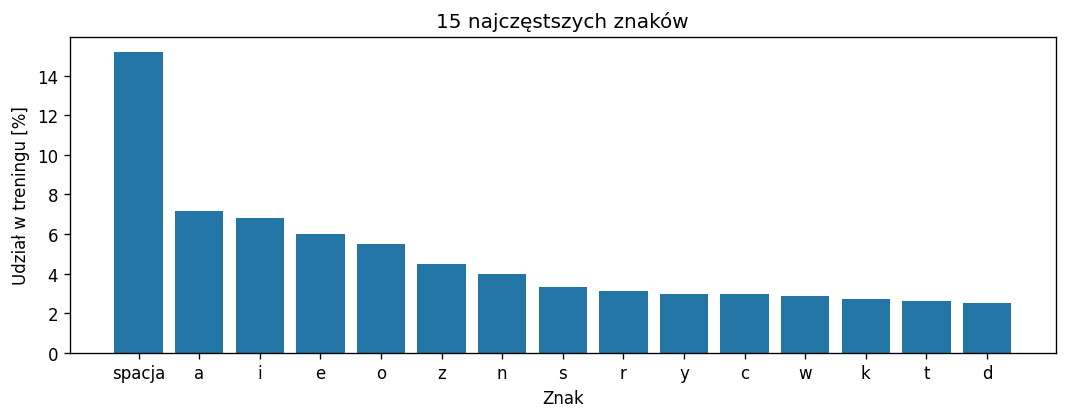

,Słowo,Liczba
0,i,2848
1,się,2560
2,w,1984
3,nie,1712
4,na,1698
5,z,1475
6,do,1210
7,że,1074
8,a,1061
9,to,830


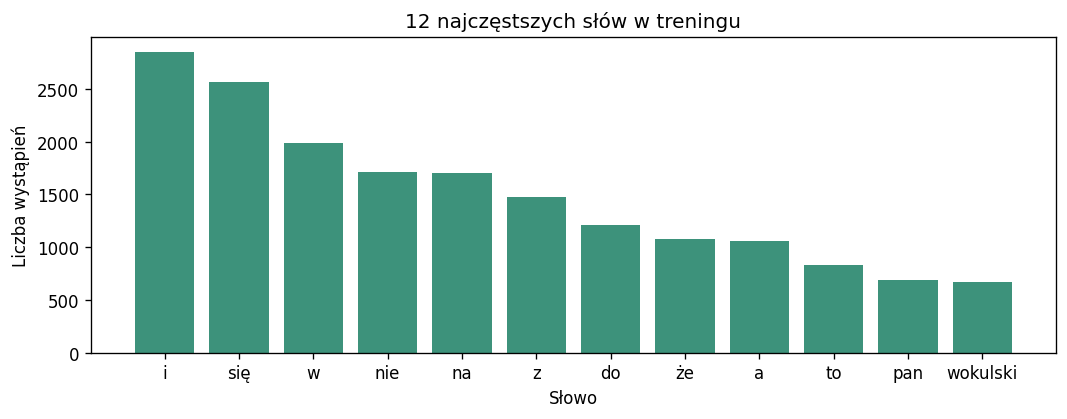

In [6]:
licznik = Counter(czesci['trening'])
top_znaki = pd.DataFrame(licznik.most_common(15), columns=['Znak', 'Liczba'])
top_znaki['Udział [%]'] = 100 * top_znaki['Liczba'] / len(czesci['trening'])
top_znaki['Znak'] = top_znaki['Znak'].replace({' ': 'spacja', '\n': 'nowa linia'})
display(top_znaki.round(3))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(top_znaki['Znak'], top_znaki['Udział [%]'], color='#2275a5')
ax.set(xlabel='Znak', ylabel='Udział w treningu [%]', title='15 najczęstszych znaków')
fig.tight_layout()
fig.savefig(wykresy / 'czestosc_znakow.png', bbox_inches='tight')
plt.show()

slowa = re.findall(r'[^\W\d_]+', czesci['trening'].lower())
top_slowa = pd.DataFrame(Counter(slowa).most_common(12), columns=['Słowo', 'Liczba'])
display(top_slowa)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(top_slowa['Słowo'], top_slowa['Liczba'], color='#3d927b')
ax.set(xlabel='Słowo', ylabel='Liczba wystąpień', title='12 najczęstszych słów w treningu')
fig.tight_layout()
fig.savefig(wykresy / 'czestosc_slow.png', bbox_inches='tight')
plt.show()

## 6. Zapis danych do laboratorium 7

In [7]:
(folder / 'korpus.txt').write_text(tekst, encoding='utf-8')
for nazwa, s in czesci.items():
    (folder / f'{nazwa}.txt').write_text(s, encoding='utf-8')
(folder / 'slownik.json').write_text(json.dumps({'stoi': stoi, 'itos': znaki, 'unk_id': stoi[UNK]}, ensure_ascii=False, indent=2), encoding='utf-8')
np.savez_compressed(folder / 'dane.npz', **{nazwa: ids.numpy() for nazwa, ids in dane.items()})
konfiguracja = {'zrodlo': url, 'autor': 'Bolesław Prus', 'tytul': 'Lalka, tom I',
                'licencja_utworu': 'domena publiczna',
                'zasady': 'https://wolnelektury.pl/info/zasady-wykorzystania/',
                'data_pobrania': '2026-11-25', 'sha256_zrodla': sha256,
                'sha256_korpusu': hashlib.sha256(tekst.encode('utf-8')).hexdigest(),
                'kodowanie': 'UTF-8', 'normalizacja': 'NFC', 'granice': granice,
                'proporcje': [0.8, 0.1, 0.1], 'sekw': SEKW, 'batch_size': BATCH,
                'krok': 1, 'seed': 0, 'V': V,
                'shuffle': {'trening': True, 'walidacja': False, 'test': False},
                'drop_last': {'trening': True, 'walidacja': False, 'test': False},
                'wersje': {'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__}}
(folder / 'konfiguracja.json').write_text(json.dumps(konfiguracja, ensure_ascii=False, indent=2), encoding='utf-8')
(folder / 'atrybucja.txt').write_text(
    'Bolesław Prus, Lalka, tom I. Źródło: Wolne Lektury.\n'
    'Tekst utworu: domena publiczna. Materiały dodatkowe: Licencja Wolnej Sztuki 1.3.\n'
    'Opracowanie redakcyjne i przypisy: Aleksandra Sekuła, Olga Sutkowska.\n'
    'Podstawa: Bolesław Prus, Lalka, przedm. Henryk Markiewicz, PIW, wyd. 31, Warszawa 1975.\n'
    'Źródło: ' + url + '\nZasady: https://wolnelektury.pl/info/zasady-wykorzystania/\n'
    'Pełna informacja wydawnicza pozostaje w pliku lalka_zrodlo.txt.\n', encoding='utf-8')
statystyki.to_csv(folder / 'statystyki.csv', index=False)
porownanie.to_csv(folder / 'porownanie_okien.csv', index=False)
wyniki = {'statystyki': statystyki.to_dict('records'), 'porownanie': porownanie.to_dict('records'),
          'kontrole': kontrole, 'nieznane': {k: dict(v) for k, v in nieznane.items()},
          'top_znaki': top_znaki.to_dict('records'), 'top_slowa': top_slowa.to_dict('records')}
(folder / 'wyniki.json').write_text(json.dumps(wyniki, ensure_ascii=False, indent=2), encoding='utf-8')
print('Zapisano korpus, podział, słownik, tablice ID, konfigurację i wyniki.')

Zapisano korpus, podział, słownik, tablice ID, konfigurację i wyniki.
